<a href="https://colab.research.google.com/github/igornvidal/apollo_analytics_academy/blob/main/An%C3%A1lise_de_ELO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

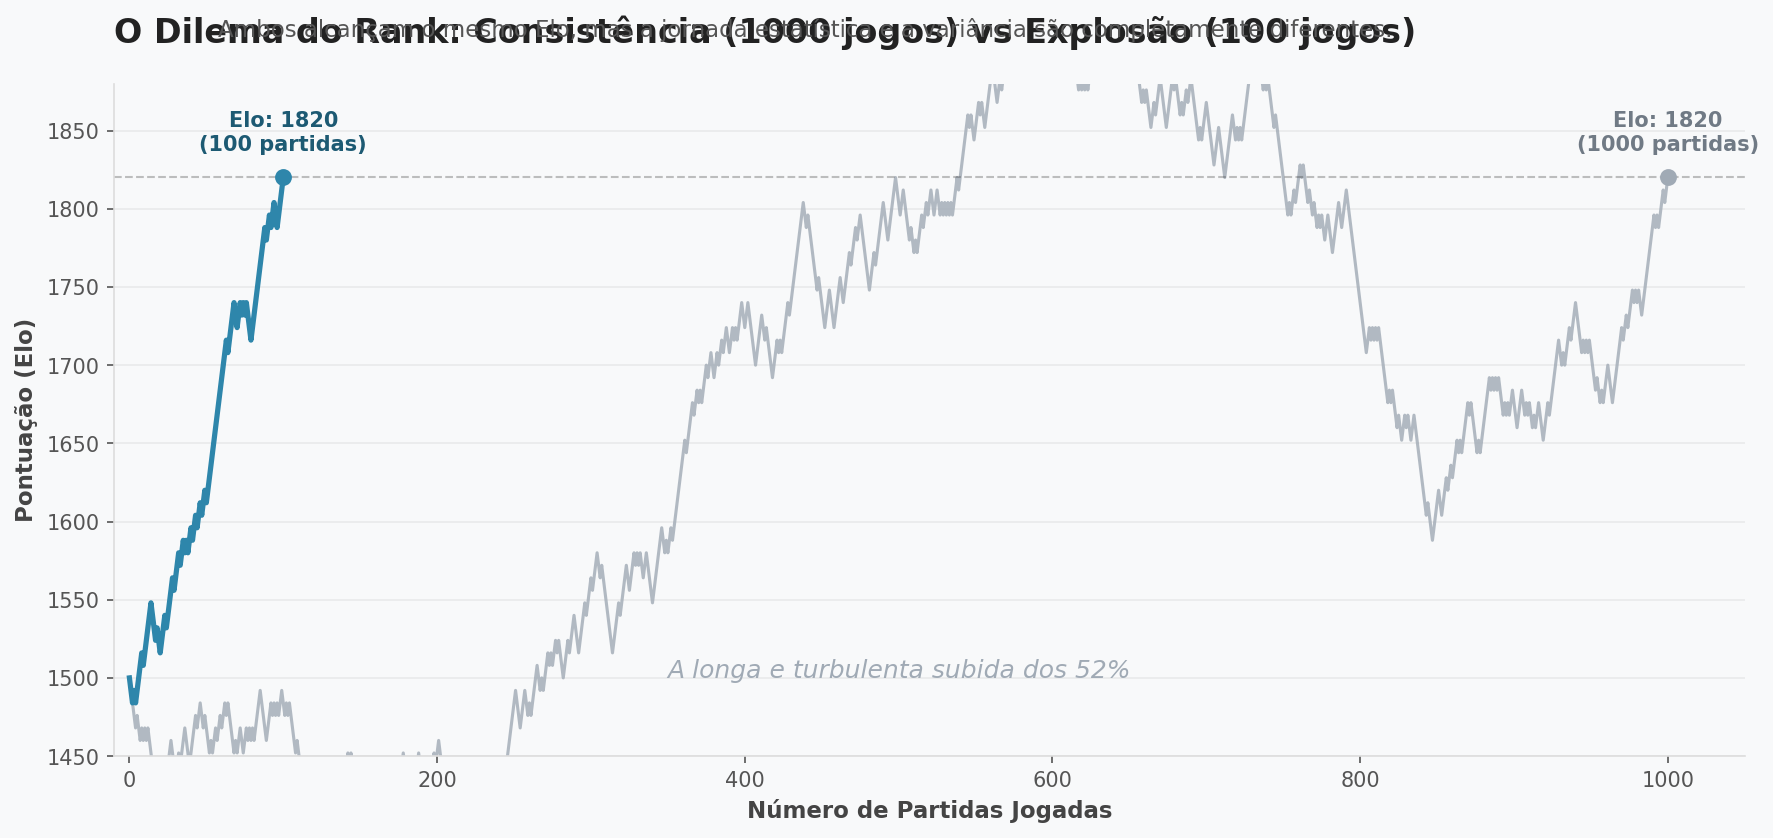

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Simulação dos Dados (Garantindo a matemática exata)
np.random.seed(42) # Para reprodutibilidade do formato da linha

elo_inicial = 1500

# Cenário A (Operário): 520 vitórias, 480 derrotas
resultados_a = [8] * 520 + [-8] * 480
np.random.shuffle(resultados_a)
elo_a = [elo_inicial] + list(elo_inicial + np.cumsum(resultados_a))
partidas_a = np.arange(1001)

# Cenário B (Prodígio): 70 vitórias, 30 derrotas
resultados_b = [8] * 70 + [-8] * 30
np.random.shuffle(resultados_b)
elo_b = [elo_inicial] + list(elo_inicial + np.cumsum(resultados_b))
partidas_b = np.arange(101)

# 2. Configuração Visual (Design minimalista e storytelling)
fig, ax = plt.subplots(figsize=(12, 6), dpi=150)
fig.patch.set_facecolor('#F8F9FA')
ax.set_facecolor('#F8F9FA')

# Removendo bordas desnecessárias (Chart Junk)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#DDDDDD')
ax.spines['bottom'].set_color('#DDDDDD')

# Plotando as linhas
linha_a, = ax.plot(partidas_a, elo_a, color='#A0AAB5', linewidth=1.5, alpha=0.8, label='Cenário A: O Operário (52% WR)')
linha_b, = ax.plot(partidas_b, elo_b, color='#2E86AB', linewidth=2.5, label='Cenário B: O Prodígio (70% WR)')

# Destacando o ponto final em comum
ax.scatter([1000], [elo_a[-1]], color='#A0AAB5', s=50, zorder=5)
ax.scatter([100], [elo_b[-1]], color='#2E86AB', s=50, zorder=5)

# Linha de referência do Elo Final
ax.axhline(y=1820, color='#333333', linestyle='--', linewidth=1, alpha=0.3)

# 3. Anotações Diretas (Melhor que legendas separadas)
ax.text(1000, elo_a[-1] + 15, 'Elo: 1820\n(1000 partidas)', color='#707A85',
        fontweight='bold', ha='center', va='bottom', fontsize=10)

ax.text(100, elo_b[-1] + 15, 'Elo: 1820\n(100 partidas)', color='#1D5A73',
        fontweight='bold', ha='center', va='bottom', fontsize=10)

ax.text(500, 1500, 'A longa e turbulenta subida dos 52%', color='#A0AAB5',
        fontsize=12, fontstyle='italic', ha='center')

# 4. Títulos e Eixos
plt.title('O Dilema do Rank: Consistência (1000 jogos) vs Explosão (100 jogos)',
          fontsize=16, fontweight='bold', color='#222222', pad=20, loc='left')

plt.suptitle('Ambos alcançam o mesmo Elo, mas a jornada estatística e a variância são completamente diferentes.',
             fontsize=11, color='#555555', x=0.125, y=0.92, ha='left')

ax.set_xlabel('Número de Partidas Jogadas', fontsize=11, fontweight='bold', color='#444444')
ax.set_ylabel('Pontuação (Elo)', fontsize=11, fontweight='bold', color='#444444')
ax.tick_params(colors='#555555')

# Configurando os limites para dar respiro ao gráfico
ax.set_xlim(-10, 1050)
ax.set_ylim(1450, 1880)

# Grid suave apenas no eixo Y para guiar os olhos
ax.grid(axis='y', linestyle='-', alpha=0.2)

# Exibindo o gráfico
plt.tight_layout()
plt.show()